In [1]:
import kagglehub
import pandas as pd
import numpy as np

In [2]:
# Download latest version
path = kagglehub.dataset_download("CooperUnion/cardataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\akul9\.cache\kagglehub\datasets\CooperUnion\cardataset\versions\1


In [3]:
df = pd.read_csv(f"{path}/data.csv")

In [4]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_') #Change all column names to be like variable names, remove casing and spaces

In [6]:
strings = list(df.dtypes[df.dtypes == 'str'].index) #get all strings from your dataset

In [7]:
#clean up the string values in each dataset 
for cols in strings:
    df[cols] = df[cols].str.lower().str.replace(' ', '_')

df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [8]:
#Explore the data

#print the column name and 
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())


make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48
model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914
year
[2011 2012 2013 1992 1993]
28
engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
10
engine_hp
[335. 300. 230. 320. 172.]
356
engine_cylinders
[ 6.  4.  5.  8. 12.]
9
transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5
driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4
number_of_doors
[ 2.  4.  3. nan]
3
market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-performance

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

#Needed to make sure all plots are displayed in a notebook
%matplotlib inline  

<Axes: xlabel='msrp', ylabel='Count'>

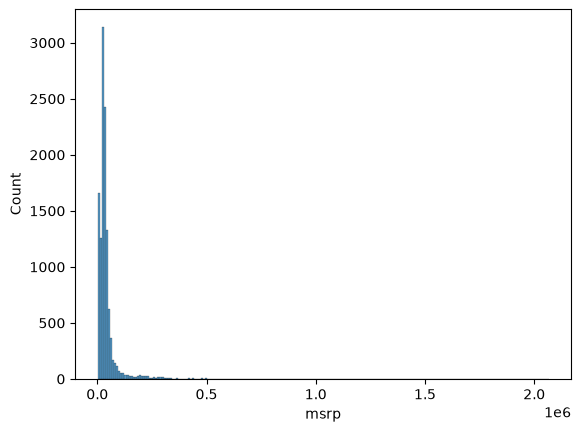

In [10]:
sns.histplot(df.msrp) 

You can see that the plot is skewed, with a large number of cars priced on the lower end. The remaining cars are  expensive and spread across a wide range. 

So let us now look at only the mid-range and lower-end cars 

<Axes: xlabel='msrp', ylabel='Count'>

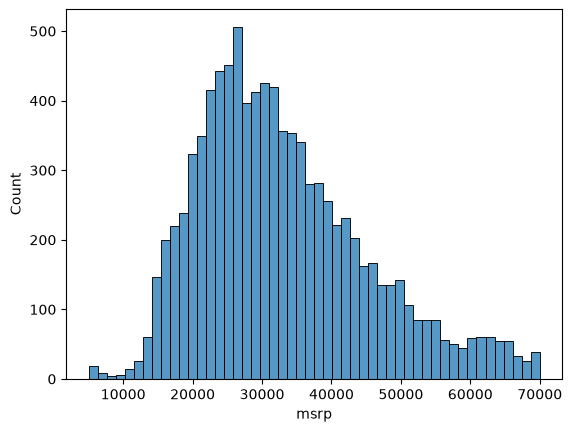

In [11]:
sns.histplot(df.msrp[(df.msrp > 5000) & (df.msrp < 70000)], bins=50) # Play around with the values to look at the data


Once you filter towards mid-range cars (below a $1M), you will notice a normal distrubition. Also notice that a noticeable number of cars are super cheap, which is not usual for a normal distribution. 

Machine learning models need the data to be normally distributed. For that, we need to convert our skewed data into a normal distribution. When there is a long tail, the easiest way to do that is to log-scale the values.

In [12]:
price_logs = np.log1p(df.msrp) #log1p adds a 1 to every value because log 0 doesn't exist (is infinity)

<Axes: xlabel='msrp', ylabel='Count'>

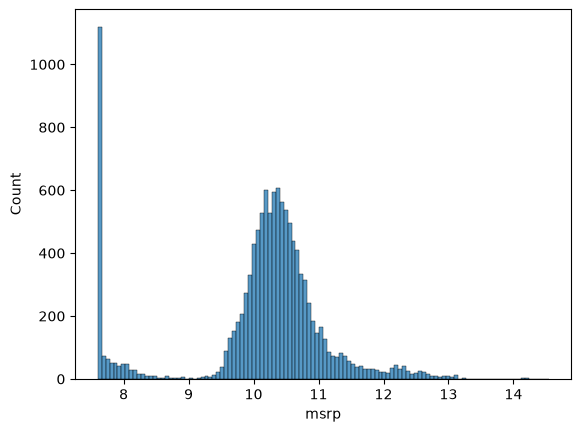

In [13]:
sns.histplot(price_logs)

Now you can see that it is almost a normal distribution, accounting for all cars in the dataset. We ignore the peak for the course. But in reality it is probably better to understand why there are so many cars priced so low? It is an artefact. If they are just random, we would just remove those cars from the dataset because we do not want to predict those cars. Or we add it as a separate feature so the model knows what type of cars are priced that way.

Next we need to understand missing values. First let us explore which columns have missing values and how many values are missing

In [14]:
df.isnull().sum() #For each column you get missing values

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

Ok now we are going to split our data into training, validation, and test. We are going to do a 60 - 20 - 20 split

In [15]:
n = len(df) #Total number of cars 

n_val = int(n * 0.2) #Int truncates the number
n_test = int(n * 0.2) #Int truncates the number
n_train = n - n_val - n_test

print(f"Total cars: {n}, Training dataset: {n_train}, Validation dataset: {n_val}, Test dataset: {n_test}")

#Check that they add up
print(f"Do they add up? Total: {n}, Sum of train, val, and test: {n_train + n_val + n_test}")

Total cars: 11914, Training dataset: 7150, Validation dataset: 2382, Test dataset: 2382
Do they add up? Total: 11914, Sum of train, val, and test: 11914


Ok now we need to select the cars and create our three datasets. Here are the steps:

1. Randomise the dataset
2. Select the first n_train rows as train dataset, then the remaining n_val rows for validation, then n_test as the final

In [16]:
#Step 1
idx = np.arange(n)
np.random.seed(2)
np.random.shuffle(idx) #np.arange(n) gets you a list of numbers from 0 to the number of cars, and then you shuffle that list

df.iloc[idx[:10]] #Check that it is randomised

#Or you can do idx = np.random.permutation(n) which gives you the final dataset 

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260
8001,volkswagen,rabbit,2008,regular_unleaded,170.0,5.0,manual,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,29,22,873,17575
2882,bentley,continental_gtc,2013,premium_unleaded_(required),500.0,8.0,automatic,all_wheel_drive,2.0,"exotic,luxury,high-performance",midsize,convertible,24,14,520,191400
649,bmw,6_series,2015,premium_unleaded_(required),315.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,coupe,32,21,3916,76100
616,maybach,57,2012,premium_unleaded_(required),543.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury",large,sedan,16,10,67,379050
4459,ford,f-150_heritage,2004,regular_unleaded,202.0,6.0,manual,four_wheel_drive,2.0,NaN,large,regular_cab_pickup,18,13,5657,26030


In [17]:
#Step 2
df_train = df.iloc[idx[:n_train]]
df_val   = df.iloc[idx[n_train:n_train+n_val]]
df_test  = df.iloc[idx[n_train+n_val:]]

(df_train), len(df_val), len(df_test)

#Log transform your outcome variable (price/msrp)
y_train = np.log1p(df_train.msrp.values)
y_val   = np.log1p(df_val.msrp.values)
y_test  = np.log1p(df_test.msrp.values)

#Remove msrp from your feature list otherwise the model will learn msrp as well!
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

Now you have created your different datasets and you are ready to fit your linear regression model. 

We are first going to train the model using the training dataset and select the relevant features. We start with a simple model

In [18]:
df_train.iloc[10]

make                                 rolls-royce
model                     phantom_drophead_coupe
year                                        2015
engine_fuel_type     premium_unleaded_(required)
engine_hp                                  453.0
engine_cylinders                            12.0
transmission_type                      automatic
driven_wheels                   rear_wheel_drive
number_of_doors                              2.0
market_category        exotic,luxury,performance
vehicle_size                               large
vehicle_style                        convertible
highway_mpg                                   19
city_mpg                                      11
popularity                                    86
Name: 7557, dtype: object

In [19]:
xi = [453, 11, 86] #Pick 3 features - engine horsepower, city mileage per gallon(mpg), popularity 

#Set your own arbitrary weights for the example
w0 = 7.17
w  = [0.01, 0.04, 0.002] 

In [20]:
def linear_regression(xi):    
    n = len(xi)
    pred = w0 
    #Loop over each feature
    for j in range(n):
        pred = pred + w[j] * xi[j]  # Multiply weight and feature and add it to your prediction
    
    return pred

In [21]:
y_pred = linear_regression(xi)
np.expm1(y_pred)

np.float64(222347.2221101062)

That is a basic structure of a linear regression for 1 car/index/row. Now we will expand the model into several cars, using vectors and matrices and use dot product instead of scalar multiplication

In [22]:
x1 = [1, 148, 24, 1385] #Car 1
x2 = [1, 132, 24, 1385] #Car 2
x3 = [1, 453, 11, 86]   #Car 3

X = [x1, x2, x3]
X = np.array(X) #Turn it into a matrix

w_new = [w0] + w #Create a vector of weights

In [23]:
def linear_regression(X, w_new):    
    return X.dot(w_new)

linear_regression(X, w_new) #This will give me a

array([12.38 , 12.22 , 12.312])

So now, you have built a matrix with x features, and multiple cars and a vector with the weights. The dot product of the feature matrix with the weights gives you the predicted value! (y = Xw)

Next, we have to figure out how we get the weights, because we have been setting the weights arbitrarily

We need to find w. We know X and y for the training data, so ideally we’d solve Xw = y by moving X to the other side: w = X⁻¹y.

However, X is an m (cars/rows) × n (features) matrix, which isn’t square, so it has no inverse. Because there are more cars than features, Xw = y also has more equations than unknowns and usually no exact solution: no single w predicts every price perfectly.
Instead, we find the w that makes Xw as close as possible to y, the one that minimises the squared errors. To do this, we multiply both sides by the transpose of X:

XᵀX w = Xᵀy

XᵀX (the Gram matrix) is square, n × n. If the features aren’t redundant (no perfect multicollinearity), it has an inverse, so:

w = (XᵀX)⁻¹ Xᵀy

If features are redundant or nearly so, XᵀX is singular or unstable, which is what regularisation fixes later in the module.

In [24]:
#Now create a feature matrix 
X = [[148, 24, 1385], 
[132, 24, 1385], 
[453, 11, 86],
[158, 24, 185],
[172, 25, 201], 
[413, 11, 86],
[38,  54, 185],
[142, 25, 431],
[453, 31, 86],
]

X = np.array(X) #Turn it into a matrix

y = [1000, 20000, 1500000, 25000, 1000, 20000, 1500000, 2050, 12000] #Known car prices

In [25]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)
    w0 = w_full[0]
    w  = w_full[1:]

    return w0, w

train_linear_regression(X, y)

(np.float64(-296019.9106334484),
 array([  820.80684851, 22412.02838059,  -277.47070644]))

Ok so we can approximate w by multiplying XTX_inverse with X transpose and y. Let us try and use our actual data to build the model

In [26]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
dtype: object

In [27]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

X_train = prepare_X(df_train)

In [28]:
w0, w = train_linear_regression(X_train, y_train)

In [29]:
y_pred = w0 + X_train.dot(w) 
y_pred

array([ 9.54792783,  9.38733977,  9.67197758, ..., 10.30423015,
       11.9778914 ,  9.99863111], shape=(7150,))

<Axes: ylabel='Count'>

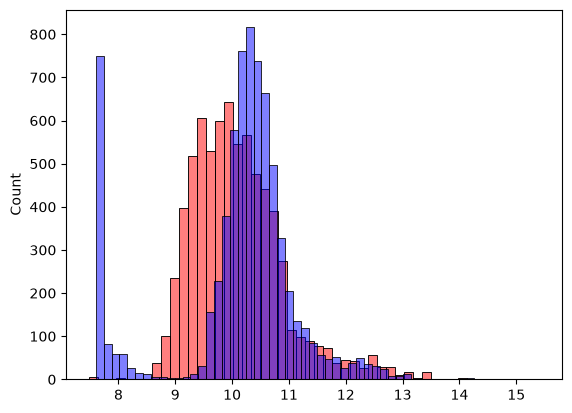

In [30]:
#Visualise model fit
sns.histplot(y_pred, color="Red", alpha = 0.5, bins = 50)  #Red is the predicted
sns.histplot(y_train, color="Blue", alpha = 0.5, bins = 50) #Blue is the true values

Ok now we have used our data to train our dataset! Next we need to evaluate model fit using root mean square error (RMSE)

RMSE is the root and mean squared difference between the actual value and the predicted value

In [31]:
def rmse(y, y_pred):
    sq_error = np.square(y_pred - y) #Error term is the difference between true and predicted, and then you square them
    mse = sq_error.mean() #You get the mean squared error
    rmse = np.sqrt(mse) #then you square root them
    return rmse

rmse(y_train, y_pred)


np.float64(0.7554192603920132)

Ok great we got our rmse which tells us the model fit. Next, let us use the trained model and validate the model with the validation dataset using RMSE

In [32]:
X_train = prepare_X(df_train)
w0, w   = train_linear_regression(X_train, y_train)

X_val   = prepare_X(df_val)
y_pred  = w0 + X_val.dot(w) 

rmse(y_val, y_pred)

np.float64(0.761653099130156)

Let us now improve the RMSE by feature engineering. 

First let us add more features. Note that there different types of data, so we will first work with continuous data

In [33]:
#Convert 'year' to 'age' relative to the current year

base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

def prepare_X(df):
    df = df.copy()
    df['age'] = 2017 - df.year
    features = base + ['age']
    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

X_train = prepare_X(df_train)

In [34]:
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_pred, y_val)

np.float64(0.5172055461058299)

<Axes: ylabel='Count'>

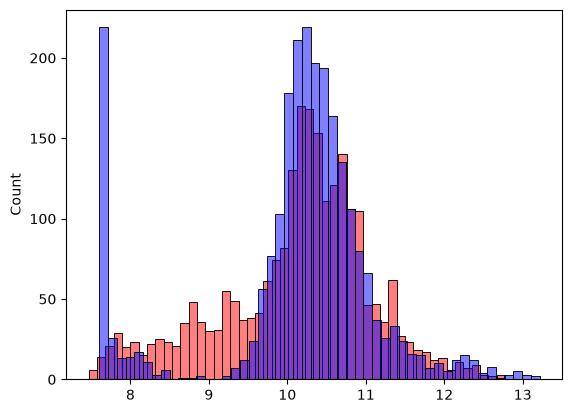

In [35]:
sns.histplot(y_pred, color = "Red", bins = 50, alpha = .5)
sns.histplot(y_val, color = "Blue", bins = 50, alpha = .5)

Let us see how to add categorical variables as features into the model. Typically they are strings but it could also be numerical (for instance, number of doors). We convert them into several columns with logical values

In [36]:
#Convert 'year' to 'age' relative to the current year

base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

def prepare_X(df):
    df = df.copy()
    features = base.copy()

    #Add continuous features
    df['age'] = 2017 - df.year
    features.append('age') 
 
    #Add categorical features
    door_values = [2,3,4]
    for i in door_values:
        df['num_doors_%s' % i] = (df.number_of_doors == i).astype('int')
        features.append('num_doors_%s' % i)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [37]:
X_train = prepare_X(df_train)

w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)

y_pred = w0 + X_val.dot(w)

rmse(y_pred, y_val)

np.float64(0.515799564150169)

In [38]:
#Now let us add the categorical variables, we add Make first
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    #Add continuous features
    df['age'] = 2017 - df.year
    features.append('age') 
 
    #Add categorical features
    door_values = [2,3,4]
    for i in door_values:
        df['num_doors_%s' % i] = (df.number_of_doors == i).astype('int')
        features.append('num_doors_%s' % i)

    makes = list(df.make.value_counts().head().index)    
    for i in makes:
        df['make_%s' % i] = (df.make == i).astype('int')
        features.append('make_%s' % i)


    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [39]:
X_train = prepare_X(df_train)

w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)

y_pred = w0 + X_val.dot(w)

rmse(y_pred, y_val)

np.float64(0.5076038849556795)

In [40]:
categories = ['make', 'engine_fuel_type', 'transmission_type', 'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style']

cat_dict = {}

for c in categories:
    cat_dict[c] = list(df[c].value_counts().head().index)

cat_dict

#Now let us add all the categorical variables
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    #Add continuous features
    df['age'] = 2017 - df.year
    features.append('age') 
 
    #Add categorical features
    door_values = [2,3,4]
    for i in door_values:
        df['num_doors_%s' % i] = (df.number_of_doors == i).astype('int')
        features.append('num_doors_%s' % i)

    for c, values in cat_dict.items():
        for v in values:
            df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c,v))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X


In [ ]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_pred, y_val)

np.float64(23.019020704791835)

Adding all the categorical variables worsened the model. The weights are all extremely large. 

This is because adding more features does not add information, and two features could be identical. Let us see what happens in that situation

In [76]:
#This matrix has two duplicate columns
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5.0001],
] 

X = np.array(X)

XTX = X.T.dot(X)
XTX

array([[140.        , 111.        , 111.0004    ],
       [111.        , 108.        , 108.0005    ],
       [111.0004    , 108.0005    , 108.00100001]])

In [77]:
#Now if we invert it

XTX_inv = np.linalg.inv(XTX) #We get a singularity error
XTX_inv

array([[ 4.12730055e-02, -6.11682842e+02,  6.11637591e+02],
       [-6.11682842e+02,  1.39187393e+08, -1.39186120e+08],
       [ 6.11637591e+02, -1.39186120e+08,  1.39184847e+08]])

Therefore having two nearly identical features will make the inverse of the gram matrix singular. Even if we do not get an error, the matrix is nearly singular and will inflate the weights as shown below. Those weights are meaningless

In [78]:
y = [1, 2, 3, 4, 5, 2]
w = XTX_inv.dot(X.T).dot(y) 
w

array([ 6.77273700e-01,  4.90300230e+03, -4.90304605e+03])

Hence we need regularisation. We add that by adding a small number (.000001 or something) to the diagonal of the gram matrix, so that it is invertable. 

In [82]:
XTX = XTX + 0.0000001*np.eye(3)
np.linalg.inv(XTX)

array([[ 0.03835867, -0.01972468, -0.01968113],
       [-0.01972468,  5.00747943, -4.98256571],
       [-0.01968113, -4.98256571,  5.00738846]])

In [ ]:
#Let us add a regularisation term to the model
def train_linear_regression(X, y, r = .001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r*np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)
    w0 = w_full[0]
    w  = w_full[1:]

    return w0, w


In [ ]:
categories = ['make', 'engine_fuel_type', 'transmission_type', 'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style']

cat_dict = {}

for c in categories:
    cat_dict[c] = list(df[c].value_counts().head(10).index)

cat_dict

#Now let us add all the categorical variables
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    #Add continuous features
    df['age'] = 2017 - df.year
    features.append('age') 
 
    #Add categorical features
    door_values = [2,3,4]
    for i in door_values:
        df['num_doors_%s' % i] = (df.number_of_doors == i).astype('int')
        features.append('num_doors_%s' % i)

    for c, values in cat_dict.items():
        for v in values:
            df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c,v))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [102]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train, r = 0.001)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_pred, y_val)

np.float64(0.45651750867781377)

Ok so adding the regularisation term improved model fit, because collinear features are corrected for. Now let's see how to choose the regularisation parameter

In [ ]:
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

for r in [0, 0.00000000001, 0.0000000001, 0.0001, 0.001, 0.1, 1, 10, 100, 1000, 10000, 1000000]:

    #Train model with chosen regularisation
    w0, w = train_linear_regression(X_train, y_train, r)
    #validate model
    y_pred = w0 + X_val.dot(w)
    rmse_score = rmse(y_pred, y_val)

    print(r, w0, rmse_score)


0 4011091003551887.0 23.019020704791835
1e-11 -2622603620823.675 0.8356337793123518
1e-10 -55384709681.64873 0.5216957288541506
0.0001 6.317246071243372 0.4565170654323052
0.001 6.285636717989048 0.45651750867781377
0.1 6.1912087238544915 0.4565692763007501
1 5.634896668066369 0.45722043179930605
10 4.283980108968471 0.4701456932099909
100 2.4990470830043594 0.578670946247553
1000 0.7765333801773293 0.9261138419765478
10000 0.13438101955379655 1.2522051591616525
1000000 0.0035816107896035083 1.7716465015046068


In [126]:
categories = ['make', 'engine_fuel_type', 'transmission_type', 'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style']

cat_dict = {}

for c in categories:
    cat_dict[c] = list(df[c].value_counts().index)

cat_dict

#Now let us add all the categorical variables
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    #Add continuous features
    df['age'] = 2017 - df.year
    features.append('age') 
 
    #Add categorical features
    door_values = [2,3,4]
    for i in door_values:
        df['num_doors_%s' % i] = (df.number_of_doors == i).astype('int')
        features.append('num_doors_%s' % i)

    for c, values in cat_dict.items():
        for v in values:
            df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c,v))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

for r in [0.00000000001, 0.0000000001, 0.0001, 0.001, 0.1, 1, 10, 100, 1000, 10000, 1000000]:

    #Train model with chosen regularisation
    w0, w = train_linear_regression(X_train, y_train, r)
    #validate model
    y_pred = w0 + X_val.dot(w)
    rmse_score = rmse(y_pred, y_val)

    print(r, w0, rmse_score)


C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perform

1e-11 -574070567326.0947 4.220618040727231
1e-10 4099740261.6447873 0.5439074463169543
0.0001 5.8902341714660436 0.4077377425145589
0.001 5.894174539220072 0.40773024639033845
0.1 5.712974099168234 0.40722082513094976
1 5.1181236887801695 0.4072935637087777
10 3.939759430828345 0.4259005724747986
100 2.361798551364695 0.5505975594188744
1000 0.7561652125100916 0.9077241477965563
10000 0.13370579657936033 1.2470723780759738
1000000 0.003581354708407704 1.771517383875059


Ok now we can choose our regularisation parameter as .0001 and we have fixed all the relevant features, let's use the model by training the data on both train and validation dataset. Then we will test it using the test dataset

In [127]:
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop = True) 

In [128]:
X_full_train = prepare_X(df_full_train)
X_test       = prepare_X(df_test)
y_full_train = np.concatenate([y_train, y_val])

w0, w = train_linear_regression(X_full_train, y_full_train, r = 1)

y_pred = w0 + X_test.dot(w)
rmse(y_pred, y_test)

C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perform

np.float64(0.3980245979591162)

Great. Now we have built our model with an RMSE of .39! Let's see how to use it in real life. If we have a new car, let's use our model to predict its price

In [131]:
df_small = pd.DataFrame([df_test.iloc[400]])
df_small

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
410,mazda,3,2017,regular_unleaded,155.0,4.0,manual,front_wheel_drive,4.0,NaN,midsize,sedan,37,27,586


In [ ]:
X_car = prepare_X(df_small)
y_pred = w0 + X_car.dot(w)

21287.060888977085
20445.000000000004


C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['%s_%s' % (c,v)] = (df[c] == v).astype('int')
C:\Users\akul9\AppData\Local\Temp\ipykernel_30760\1510575297.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perform

In [142]:
print(float(np.expm1(y_pred[0])))

print(float(np.expm1(y_test[400])))

21287.060888977085
20445.000000000004
